(sec-11-2)=
# 11.2 Recording the ECG: Leads, Amplifiers, Anti-Aliasing and Sampling

Every ECG analyzed in this book has already been shaped by hardware before the first line of Python touches it. A pair of silver chloride electrodes turned ionic currents into electronic ones, an instrumentation amplifier rejected a common-mode voltage hundreds of times larger than the heart's signal, a coupling capacitor removed the electrode offset (and, if it was poorly chosen, part of the ST segment), an analog low-pass filter tried to keep muscle noise and mains harmonics out of the converter, and an analog-to-digital converter chose how finely to slice time and amplitude. Each of these steps leaves fingerprints in the data, and some of them cannot be undone by any later processing.

I find it useful to keep this chain in mind whenever an ECG algorithm misbehaves, because a surprising number of apparent signal processing problems were decided at the front end, long before the data reached a computer. In this section I follow the ECG from the skin to the sample. We look at electrodes and lead systems, derive the gain and common-mode rejection of the instrumentation amplifier, show what AC coupling does to the ST segment, and then work through two experiments on real data step by step: re-digitizing a noisy MIT-BIH recording with and without an anti-aliasing filter, and measuring how the sampling rate affects R-peak amplitude and timing. The general acquisition chain was introduced in [Section 1.3](../ch01_introduction/03_acquisition_chain.ipynb); here everything is specific to the ECG.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
from scipy import signal
from matplotlib.patches import FancyBboxPatch

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

(sec-11-2-1)=
## 11.2.1 The Signal Chain at a Glance

The block diagram below shows a typical single-channel ECG front end. Not every device has every block, and modern designs move some of them into the digital domain, but the order of operations is almost universal.

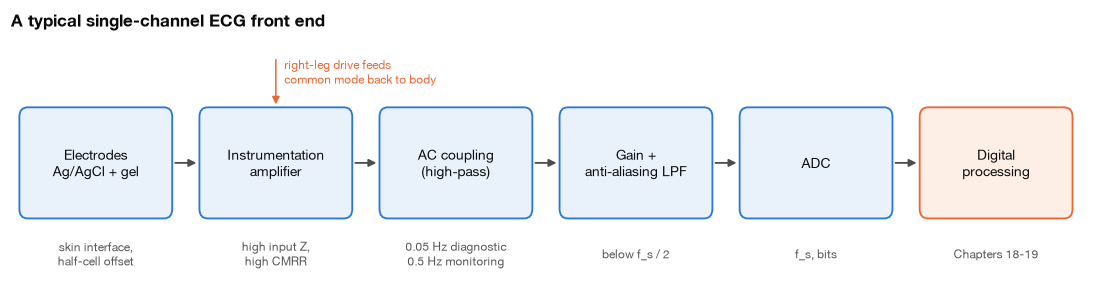

In [2]:
blocks = [("Electrodes\nAg/AgCl + gel", "skin interface,\nhalf-cell offset"),
          ("Instrumentation\namplifier", "high input Z,\nhigh CMRR"),
          ("AC coupling\n(high-pass)", "0.05 Hz diagnostic\n0.5 Hz monitoring"),
          ("Gain +\nanti-aliasing LPF", "below f_s / 2"),
          ("ADC", "f_s, bits"),
          ("Digital\nprocessing", "Chapters 18-19")]
fig, ax = plt.subplots(figsize=(10, 2.6))
w, h, gap = 1.42, 0.9, 0.3
for k, (name, note) in enumerate(blocks):
    x0 = k * (w + gap)
    face = "#e9f1fb" if k < 5 else "#fdeee6"
    ax.add_patch(FancyBboxPatch((x0, 0), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=face, ec=C[0] if k < 5 else C[1], lw=1.2))
    ax.text(x0 + w / 2, h / 2, name, ha="center", va="center", fontsize=9)
    ax.text(x0 + w / 2, -0.32, note, ha="center", va="center", fontsize=7.8, color="0.35")
    if k < len(blocks) - 1:
        ax.annotate("", xy=(x0 + w + gap - 0.02, h / 2), xytext=(x0 + w + 0.02, h / 2),
                    arrowprops=dict(arrowstyle="-|>", color="0.3", lw=1.2))
ax.annotate("", xy=(1 * (w + gap) + w / 2, h + 0.02), xytext=(1 * (w + gap) + w / 2, h + 0.45),
            arrowprops=dict(arrowstyle="-|>", color=C[1], lw=1.0))
ax.text(1 * (w + gap) + w / 2 + 0.08, h + 0.32, "right-leg drive feeds\ncommon mode back to body",
        fontsize=7.8, color=C[1], va="center")
ax.set(xlim=(-0.1, 6 * (w + gap)), ylim=(-0.6, 1.5), title="A typical single-channel ECG front end")
ax.axis("off")
plt.show()

The rest of the section walks along this chain from left to right.

(sec-11-2-2)=
## 11.2.2 Electrodes and the Skin Interface

Inside the body, current is carried by ions; in the amplifier, by electrons. The electrode is where one becomes the other. The standard ECG electrode is a silver disc coated with silver chloride (Ag/AgCl) and covered with an electrolyte gel. At its surface the reversible reaction

$$
\mathrm{Ag} + \mathrm{Cl}^- \;\rightleftharpoons\; \mathrm{AgCl} + e^-
$$

lets charge cross the interface easily in both directions. Electrodes of this kind are called **non-polarizable**: current passes without building up a large charge layer, so the interface behaves mostly like a resistor and generates little low-frequency noise.

Every metal–electrolyte interface also develops a **half-cell potential**, about $+0.22$ V for Ag/AgCl. Two identical electrodes would cancel each other, but real electrodes differ slightly in chemistry, gel and skin contact, and the difference appears between the amplifier inputs as a DC offset of a few to a few hundred millivolts. Standards for electrocardiographs require the input stage to tolerate offsets of up to $\pm 300$ mV {cite:p}`webster2010`, which is three hundred times the amplitude of a typical QRS complex. This single number explains why the first amplifier stage of an ECG front end usually has a modest gain, and why the signal is AC-coupled before most of the amplification happens.

The skin itself is the larger obstacle. Its outer layer, the stratum corneum, is made of dead, dry cells with a high resistance, shunted by a capacitance. A common equivalent circuit puts the half-cell potential in series with a resistance $R_s$ (gel and deeper tissue) and a parallel combination $R_d \parallel C_d$ (interface and skin):

(eq-11-13)=
\begin{equation*}
Z_e(f) = R_s + \frac{R_d}{1 + j2\pi f R_d C_d}. \tag{11.13}
\end{equation*}

At low frequencies the capacitor is open and $Z_e \approx R_s + R_d$; at high frequencies it shorts $R_d$ and $Z_e \to R_s$. Gel hydrates the skin and lowers $R_d$ dramatically, which is why clinical electrodes use it and why the dry or textile electrodes of many wearables present much higher impedances. The numbers below are illustrative orders of magnitude rather than measurements of a particular product; real values vary widely with skin preparation, humidity and time.

In [3]:
def electrode_impedance(f, R_s, R_d, C_d):
    """Skin-electrode impedance (ohm) of the series R + (R || C) model, equation (17.13)."""
    return R_s + R_d / (1 + 2j * np.pi * f * R_d * C_d)


models = {"wet Ag/AgCl, prepared skin": (200.0, 20e3, 1e-6),
          "dry electrode": (500.0, 2e6, 10e-9)}
freqs = np.array([0.5, 10.0, 40.0])
rows = {name: np.abs(electrode_impedance(freqs, *p)) / 1e3 for name, p in models.items()}
print(pd.DataFrame(rows, index=[f"{f:g} Hz" for f in freqs]).T.round(1)
      .to_string(header=[f"|Z| at {f:g} Hz (kOhm)" for f in freqs]))

                           |Z| at 0.5 Hz (kOhm) |Z| at 10 Hz (kOhm) |Z| at 40 Hz (kOhm)
wet Ag/AgCl, prepared skin                 20.2                12.6                 3.9
dry electrode                            1996.6              1245.7               390.3


The dry electrode's impedance is about a hundred times larger in the ECG band, and it changes with frequency, so it also distorts the low-frequency content if the amplifier input impedance is not much larger still. We quantify that requirement in [Section 11.2.4](#sec-11-2-4).

Two more electrode effects matter for signal processing. Stretching the skin under an electrode changes the skin's own potential by up to several millivolts, producing **electrode motion artifact**, the hardest ECG noise to remove because its spectrum overlaps the ECG's. And a slowly drying gel lets the offset drift, which adds to the baseline wander caused by breathing. Both are treated in [Section 12.1](../ch18_ecg_preprocessing/01_ecg_noise_types.ipynb), using real recordings from the MIT-BIH Noise Stress Test Database {cite:p}`moody1984`.

(sec-11-2-3)=
## 11.2.3 Lead Systems in Practice

[Section 11.1](01_cardiac_electrophysiology.ipynb) derived the standard 12-lead ECG from the heart-vector model. Diagnostic electrocardiographs record those twelve leads for ten seconds with the patient lying still. Long-term recordings use far fewer electrodes, placed where they stay put.

- **Holter and monitoring leads.** Ambulatory recorders use two or three bipolar channels with all electrodes on the torso, because limb electrodes move too much. The MIT-BIH Arrhythmia Database, recorded on two-channel Holter tapes, uses a *modified limb lead II* (MLII) obtained with chest electrodes in its upper channel and, in most records, a modified chest lead V1 in its lower channel (V5 in record 100) {cite:p}`moody2001`. Bedside monitors similarly place the "limb" electrodes on the shoulders and lower torso (the Mason–Likar positions), which slightly changes the waveform compared with true limb leads.
- **Single-lead wearables.** Smartwatches record a lead-I-like signal between the wrist under the watch and a finger of the other hand. Adhesive chest patches record a short bipolar lead between two electrodes a few centimeters apart.

The lead choice changes the waveform a great deal, which matters for any algorithm trained on one lead and applied to another. The header of each MIT-BIH record tells us which leads it contains.

In [4]:
for record in ["100", "119"]:
    hdr = wfdb.rdheader(f"../data/mitdb/{record}")
    print(f"record {record}: leads {hdr.sig_name}, fs = {hdr.fs} Hz, comments: {hdr.comments}")

record 100: leads ['MLII', 'V5'], fs = 360 Hz, comments: ['69 M 1085 1629 x1', 'Aldomet, Inderal']
record 119: leads ['MLII', 'V1'], fs = 360 Hz, comments: ['51 F 1129 654 x2', 'Pronestyl', 'The PVCs are uniform.']


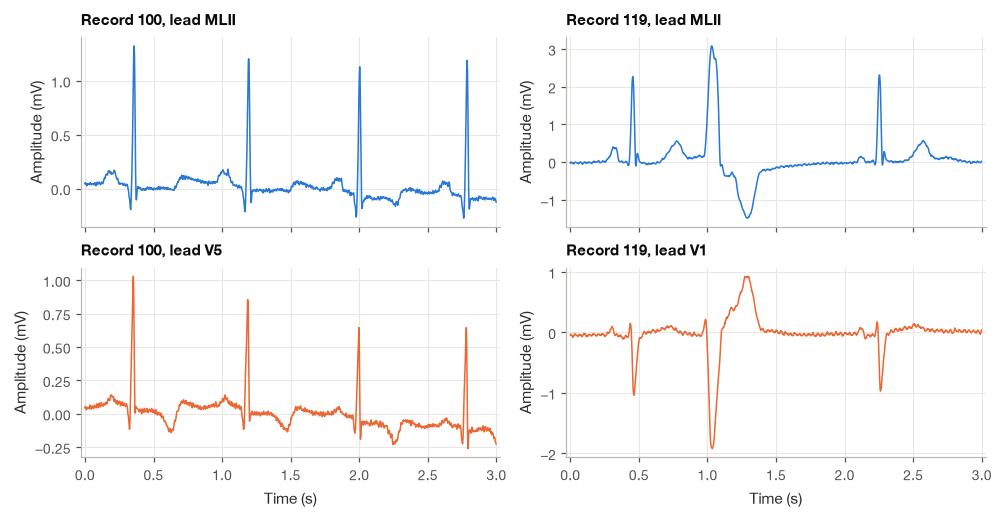

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(9, 4.6), sharex=True)
for j, (record, t_start) in enumerate([("100", 60.0), ("119", 60.0)]):
    rec = wfdb.rdrecord(f"../data/mitdb/{record}", sampfrom=int(t_start * 360), sampto=int((t_start + 3) * 360))
    t = np.arange(rec.sig_len) / rec.fs
    for i in range(2):
        x = rec.p_signal[:, i] - np.median(rec.p_signal[:, i])
        axes[i, j].plot(t, x, color=C[i], lw=1)
        axes[i, j].set_title(f"Record {record}, lead {rec.sig_name[i]}", fontsize=10)
        axes[i, j].set_ylabel("Amplitude (mV)")
for ax in axes[-1]:
    ax.set_xlabel("Time (s)")
plt.show()

In record 100 the two leads look similar, both dominated by upright R waves, because MLII and V5 both look roughly along the main direction of left ventricular activation. In record 119 the normal beats are upright in MLII and mostly negative in V1, which views the heart from the right front of the chest, while the premature ventricular beat changes shape differently in the two leads. A QRS detector tuned to upright R waves would struggle on V1, and this is one reason that most published detectors, including the one in Section 19.1, are evaluated on the MLII channel.

### Why short electrode spacing means small signals

The lead-vector result $V = \mathbf{p}\cdot\mathbf{l}$ from [Section 11.1](01_cardiac_electrophysiology.ipynb) has a practical consequence for wearables: closely spaced electrodes record a smaller signal. We can see how much smaller with the dipole potential of equation (11.1), placing a dipole of fixed moment at depth $d$ below the midpoint of an electrode pair with spacing $s$, aligned with the pair. The two electrodes sit at $\pm s/2$ along the dipole axis, at distance $\sqrt{(s/2)^2 + d^2}$ from it, so

$$
V(s) = \Phi\!\left(+\tfrac{s}{2}\right) - \Phi\!\left(-\tfrac{s}{2}\right)
= \frac{2\,p\,(s/2)}{4\pi\sigma\left[(s/2)^2 + d^2\right]^{3/2}}
\;\approx\; \frac{p\,s}{4\pi\sigma\,d^3} \quad (s \ll d).
$$

For a pair that is small compared with its distance from the heart, the voltage grows in proportion to the spacing. The growth stops when the spacing becomes comparable with the depth: setting $dV/ds = 0$ gives a maximum at $s/2 = d/\sqrt{2}$, after which the electrodes move away from the dipole faster than the lever arm grows.

In [6]:
def dipole_potential(r, p, sigma=0.2):
    """Far-field potential (V) of a current dipole at the origin, equation (17.1)."""
    return p @ r / (4 * np.pi * sigma * np.linalg.norm(r) ** 3)


p_heart = np.array([2.5e-5, 0.0, 0.0])              # A m, gives about 1 mV for a wide pair
depth = 0.08                                        # m, heart to skin
for spacing_cm in [1, 2, 4, 8, 11.3, 20]:
    s = spacing_cm / 100
    v = (dipole_potential(np.array([s / 2, 0, depth]), p_heart)
         - dipole_potential(np.array([-s / 2, 0, depth]), p_heart))
    print(f"electrode spacing {spacing_cm:5.1f} cm  ->  lead voltage {1e3 * v:.2f} mV")

electrode spacing   1.0 cm  ->  lead voltage 0.19 mV
electrode spacing   2.0 cm  ->  lead voltage 0.38 mV
electrode spacing   4.0 cm  ->  lead voltage 0.71 mV
electrode spacing   8.0 cm  ->  lead voltage 1.11 mV
electrode spacing  11.3 cm  ->  lead voltage 1.20 mV
electrode spacing  20.0 cm  ->  lead voltage 0.95 mV


Below about 4 cm, halving the spacing halves the signal, while the noise from the electrodes and the amplifier does not shrink. In this idealized geometry the voltage peaks at $s = \sqrt{2}\,d \approx 11.3$ cm and falls slowly beyond it; real torsos are not infinite homogeneous conductors, but the conclusion holds. A 2 cm patch needs a much quieter front end than a 10 cm one to reach the same signal-to-noise ratio.

(sec-11-2-4)=
## 11.2.4 The Instrumentation Amplifier and Common-Mode Rejection

The body is a conductor surrounded by mains wiring. Capacitive coupling drives a small displacement current through it, and the whole body floats at a power-line potential relative to the amplifier's ground. This **common-mode** voltage is identical at both ECG electrodes and can be tens or hundreds of millivolts; the ECG is the tiny **differential** voltage between them. The amplifier must amplify the difference and ignore the common part.

Writing the two input voltages as $v_a$ and $v_b$, we define the differential and common-mode components

$$
v_d = v_a - v_b, \qquad v_c = \frac{v_a + v_b}{2}, \qquad v_{\text{out}} = A_d\,v_d + A_c\,v_c,
$$

and the **common-mode rejection ratio** $\mathrm{CMRR} = |A_d / A_c|$, usually quoted in decibels as $20\log_{10}\mathrm{CMRR}$.

### The three-op-amp instrumentation amplifier

The classic circuit has two stages. In the **input stage**, each input drives the non-inverting input of an op-amp, so the input impedance is very high. The two op-amps are joined by resistors $R_1$, $R_g$, $R_1$ in series between their outputs. An ideal op-amp holds its two inputs at the same voltage, so the ends of $R_g$ sit at $v_a$ and $v_b$ and the current through it is

$$
i = \frac{v_a - v_b}{R_g}.
$$

No current enters the op-amp inputs, so the same current flows through both $R_1$ resistors, and the stage outputs are

$$
v_1 = v_a + i R_1, \qquad v_2 = v_b - i R_1
\quad\Longrightarrow\quad
v_1 - v_2 = (v_a - v_b)\left(1 + \frac{2R_1}{R_g}\right).
$$

The difference is amplified by $G_1 = 1 + 2R_1/R_g$, while a common-mode input ($v_a = v_b$) gives $i = 0$ and passes to both outputs with gain one.

The **output stage** is a difference amplifier. Its op-amp receives $v_2$ at the inverting input through $R_2$ (feedback $R_3$) and $v_1$ at the non-inverting input through a divider $R_2'$, $R_3'$ to ground. The non-inverting input sits at $v_+ = v_1 R_3'/(R_2' + R_3')$, and the inverting input is held at the same voltage. Kirchhoff's current law at the inverting node, $(v_2 - v_+)/R_2 = (v_+ - v_{\text{out}})/R_3$, solved for the output, gives

(eq-11-14)=
\begin{equation*}
v_{\text{out}} = v_1\,\frac{R_3'}{R_2' + R_3'}\left(1 + \frac{R_3}{R_2}\right) - v_2\,\frac{R_3}{R_2}. \tag{11.14}
\end{equation*}

If the resistors are perfectly matched ($R_2' = R_2$, $R_3' = R_3$), the first coefficient simplifies to $R_3/R_2$ and $v_{\text{out}} = (R_3/R_2)(v_1 - v_2)$: a pure difference. If one resistor is off by a small fraction $\varepsilon$, say $R_3' = R_3(1 + \varepsilon)$ with $R_2 = R_3$, the two coefficients in [(11.14)](#eq-11-14) no longer match, and a common-mode input $v_1 = v_2 = v_c$ leaks through with gain

$$
A_{c,2} = \frac{2(1 + \varepsilon)}{2 + \varepsilon} - 1 = \frac{\varepsilon}{2 + \varepsilon} \approx \frac{\varepsilon}{2}.
$$

The stage alone therefore has $\mathrm{CMRR}_2 \approx 2/\varepsilon$, which is only about 1000 (60 dB) for a 0.2 % mismatch. The input stage helps: it multiplies the differential signal by $G_1$ but leaves the common mode untouched, so the overall rejection becomes approximately $G_1 \cdot \mathrm{CMRR}_2$. We verify these formulas by evaluating [(11.14)](#eq-11-14) directly.

In [7]:
def in_amp(v_a, v_b, R1, Rg, R2, R3, R2p, R3p):
    """Ideal-op-amp three-op-amp instrumentation amplifier output, equation (17.14)."""
    i = (v_a - v_b) / Rg
    v1, v2 = v_a + i * R1, v_b - i * R1
    return v1 * R3p / (R2p + R3p) * (1 + R3 / R2) - v2 * R3 / R2


R1, Rg = 24.9e3, 5.53e3                      # first-stage gain about 10
R2 = R3 = R2p = 10e3
eps = 0.002                                  # 0.2 % mismatch in one resistor
R3p = R3 * (1 + eps)

A_d = in_amp(0.5e-3, -0.5e-3, R1, Rg, R2, R3, R2p, R3p) / 1e-3
A_c = in_amp(1.0, 1.0, R1, Rg, R2, R3, R2p, R3p) / 1.0
G1 = 1 + 2 * R1 / Rg
print(f"first-stage gain G1     = {G1:.2f}")
print(f"differential gain A_d   = {A_d:.2f}")
print(f"common-mode gain A_c    = {A_c:.2e}   (eps / (2 + eps) = {eps / (2 + eps):.2e})")
print(f"CMRR                    = {20 * np.log10(abs(A_d / A_c)):.1f} dB "
      f"(prediction G1 * 2/eps: {20 * np.log10(G1 * (2 + eps) / eps):.1f} dB)")

first-stage gain G1     = 10.01
differential gain A_d   = 10.01
common-mode gain A_c    = 9.99e-04   (eps / (2 + eps) = 9.99e-04)
CMRR                    = 80.0 dB (prediction G1 * 2/eps: 80.0 dB)


A first-stage gain of 10 lifts the rejection from 60 to 80 dB. We cannot simply raise $G_1$ to 1000, because the $\pm 300$ mV electrode offset would then saturate the input stage; this is the design tension that AC coupling, or a converter with enough dynamic range to digitize the offset, resolves.

### Input impedance and the potential-divider effect

Even a perfect amplifier cannot reject common-mode voltage that has already been converted into a differential one. Each electrode impedance $Z_{e1}$, $Z_{e2}$ forms a voltage divider with the amplifier's common-mode input impedance $Z_{cm}$. A common-mode voltage $v_c$ on the body reaches the two inputs as

$$
v_c\,\frac{Z_{cm}}{Z_{cm} + Z_{e1}} \quad\text{and}\quad v_c\,\frac{Z_{cm}}{Z_{cm} + Z_{e2}},
$$

and their difference is an error that looks exactly like ECG. For $Z_{cm} \gg Z_e$ we can expand each fraction as $1 - Z_e/Z_{cm}$ to first order, giving

(eq-11-15)=
\begin{equation*}
v_{d,\text{error}} \approx v_c\,\frac{Z_{e2} - Z_{e1}}{Z_{cm}}. \tag{11.15}
\end{equation*}

**Example 11.2.1.** The body floats at 100 mV of 60 Hz relative to the amplifier reference, and the two electrode impedances differ by 20 kΩ. How large is the 60 Hz error for $Z_{cm} = 10$ MΩ and for $Z_{cm} = 1$ GΩ?

By [(11.15)](#eq-11-15), $0.1 \times 20\times10^3 / 10^7 = 0.2$ mV in the first case, a fifth of a QRS complex, and $0.1 \times 20\times10^3/10^9 = 2$ µV in the second. Two lessons follow: amplifier input impedances for ECG must be very high (and dry electrodes, with their much larger and more variable impedances, make this harder), and reducing $v_c$ itself is as valuable as improving the amplifier.

### Right-leg drive

Reducing $v_c$ is the job of the **right-leg drive**. The circuit senses the common-mode voltage (the average of the two inputs), inverts and amplifies it with gain $G$, and drives it back into the body through the right-leg electrode. A simple model shows why this works. Without feedback, the displacement current $i_d$ flows to ground through the right-leg electrode impedance $R_{RL}$, so $v_c = i_d R_{RL}$. With feedback, the right-leg electrode is driven to $-G v_c$, so

$$
v_c = i_d R_{RL} - G\,v_c \quad\Longrightarrow\quad v_c = \frac{i_d R_{RL}}{1 + G}.
$$

The common-mode voltage shrinks by the loop gain, often a factor of 10 to 100. In practice the gain is limited by stability, and a series resistor keeps the current into the patient within the safety limits that medical device standards impose {cite:p}`webster2010`. The power-line interference that still gets through is removed digitally in Section 18.4.

(sec-11-2-5)=
## 11.2.5 AC Coupling: The High-Pass Corner and the ST Segment

To keep the electrode offset out of the later gain stages, the signal passes through a high-pass filter, in the simplest case a series capacitor $C$ and a resistor $R$ to ground. Its transfer function and frequency response (see Section 8.4) are

$$
H(s) = \frac{s\tau}{1 + s\tau}, \qquad
|H(f)| = \frac{2\pi f\tau}{\sqrt{1 + (2\pi f\tau)^2}}, \qquad
\angle H(f) = 90^\circ - \arctan(2\pi f \tau),
$$

with $\tau = RC$ and corner frequency $f_c = 1/(2\pi\tau)$. Diagnostic recommendations specify $f_c = 0.05$ Hz for this kind of filter, while monitors often use 0.5 Hz or more to suppress baseline wander; a linear-phase digital filter can go up to about 0.67 Hz without the distortion described below {cite:p}`kligfield2007`. The question is why the conservative 0.05 Hz figure matters.

### What a first-order high-pass does to the ST segment

Rewrite the transfer function as $H(s) = 1 - \frac{1}{1 + s\tau}$. The output is the input minus a low-pass filtered copy of itself, $y = x - v$, where the low-pass output $v$ obeys the first-order differential equation

$$
\tau\,\frac{dv}{dt} + v = x .
$$

Moving $v$ to the right-hand side gives $\tau\,dv/dt = x - v = y$: the low-pass state changes at a rate proportional to the *output* of the high-pass filter. Integrating this from an instant $t_1$ in the PR segment to an instant $t_2$ in the ST segment,

$$
v(t_2) - v(t_1) = \frac{1}{\tau}\int_{t_1}^{t_2} y(s)\,ds .
$$

Because $y = x - v$, the ST level measured relative to the PR level, $y(t_2) - y(t_1)$, differs from the same quantity in the input by exactly $-(v(t_2) - v(t_1))$:

(eq-11-16)=
\begin{equation*}
\big[y(t_2) - y(t_1)\big] - \big[x(t_2) - x(t_1)\big] = -\frac{1}{\tau}\int_{t_1}^{t_2} y(s)\,ds . \tag{11.16}
\end{equation*}

Equation [(11.16)](#eq-11-16) holds for any waveform. The filter lowers the ST segment, relative to the PR segment, by the area of its own output between the two instants divided by the time constant. Between the PR and ST segments lies the QRS complex. If the corner frequency is low, the output is the input with a slowly varying offset removed, and if we further assume that the cycle's mean level equals the PR level, the area between $t_1$ and $t_2$ is just the net QRS area $A_{\text{QRS}}$ measured above the PR level. This gives a rule of thumb that is easy to remember:

(eq-11-17)=
\begin{equation*}
\Delta_{\text{ST}} \approx -\frac{A_{\text{QRS}}}{\tau} = -2\pi f_c\,A_{\text{QRS}}. \tag{11.17}
\end{equation*}

A positive QRS pushes the ST segment *down*, by an amount proportional to the corner frequency. For a QRS area of 25 mV·ms, equation [(11.17)](#eq-11-17) predicts 8 µV at 0.05 Hz but 79 µV at 0.5 Hz, close to the 0.1 mV deviations that clinicians examine when they look for ischemia. A causal 0.5 Hz high-pass can thus create an ST depression that the heart did not produce.

We test both equations on record 100. The recording already passed through the Holter's own analog filter, so we measure the *additional* change in the ST level, relative to the PR baseline, that a further first-order high-pass produces. We compare it with the rule of thumb, computed from the net QRS area of the recorded beats, and with the exact identity, computed from the area of the filtered average beat between the PR and ST windows.

In [8]:
rec = wfdb.rdrecord("../data/mitdb/100", sampto=360 * 180, channels=[0])
fs = rec.fs
ecg100 = rec.p_signal[:, 0]
ann = wfdb.rdann("../data/mitdb/100", "atr", sampto=360 * 180)
r_peaks = np.array([s for s, sym in zip(ann.sample, ann.symbol) if sym == "N"])
r_peaks = r_peaks[(r_peaks > 20 * fs) & (r_peaks < ecg100.size - fs)]   # skip the filter start-up


def average_beat(x, peaks, fs, before=0.3, after=0.5):
    """Ensemble average of beats aligned on their R peaks."""
    idx = np.arange(-int(before * fs), int(after * fs))
    return idx / fs, np.mean([x[p + idx] for p in peaks], axis=0)


t_b, beat_orig = average_beat(ecg100, r_peaks, fs)
pr_win = (t_b > -0.07) & (t_b < -0.04)            # PR baseline, 70 to 40 ms before R
st_win = (t_b > 0.09) & (t_b < 0.11)              # ST level, 100 ms after R
qrs_win = (t_b > -0.06) & (t_b < 0.06)
pr_level = beat_orig[pr_win].mean()
area_qrs = np.sum(beat_orig[qrs_win] - pr_level) / fs * 1000           # mV ms
print(f"net QRS area of the average beat: {area_qrs:.1f} mV ms")

rows, beats_hp = [], {}
for fc in [0.05, 0.5, 1.0]:
    tau = 1 / (2 * np.pi * fc)
    b, a = signal.butter(1, fc, btype="highpass", fs=fs)               # first-order, causal
    _, beat_hp = average_beat(signal.lfilter(b, a, ecg100), r_peaks, fs)
    beats_hp[fc] = beat_hp
    measured = 1000 * ((beat_hp[st_win].mean() - beat_hp[pr_win].mean())
                       - (beat_orig[st_win].mean() - pr_level))
    area_out = np.cumsum(beat_hp) / fs                                  # running area of y (mV s)
    exact = -1000 * (area_out[st_win].mean() - area_out[pr_win].mean()) / tau   # (17.16)
    rule = -2 * np.pi * fc * area_qrs                                   # (17.17), uV
    rows.append([f"{fc:g}", rule, exact, measured, 1000 * beat_hp[pr_win].mean()])
print(pd.DataFrame(rows, columns=["f_c (Hz)", "rule (17.17) (uV)", "identity (17.16) (uV)",
                                  "measured (uV)", "output at PR (uV)"]).round(1).to_string(index=False))

net QRS area of the average beat: 18.3 mV ms
f_c (Hz)  rule (17.17) (uV)  identity (17.16) (uV)  measured (uV)  output at PR (uV)
    0.05               -5.7                   -2.9           -2.9              -49.1
     0.5              -57.4                  -18.2          -18.4              -53.2
       1             -114.9                  -19.6          -20.0              -57.2


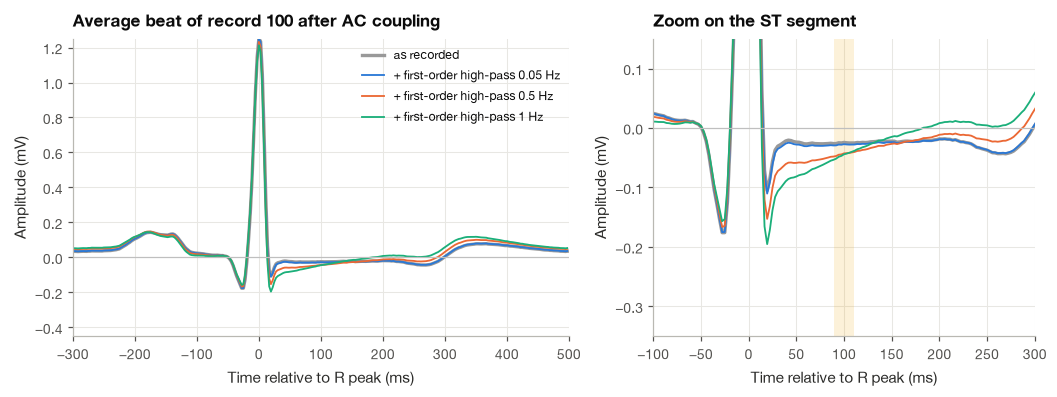

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.5), gridspec_kw={"width_ratios": [1.3, 1]})
for ax, (xlim, ylim) in zip(axes, [((-300, 500), (-0.45, 1.25)), ((-100, 300), (-0.35, 0.15))]):
    ax.plot(1000 * t_b, beat_orig - pr_level, color="0.6", lw=2.2, label="as recorded")
    for k, fc in enumerate([0.05, 0.5, 1.0]):
        beat = beats_hp[fc]
        ax.plot(1000 * t_b, beat - beat[pr_win].mean(), color=C[k], lw=1.2,
                label=f"+ first-order high-pass {fc:g} Hz")
    ax.axhline(0, color="0.75", lw=0.8)
    ax.set(xlim=xlim, ylim=ylim, xlabel="Time relative to R peak (ms)", ylabel="Amplitude (mV)")
axes[0].set_title("Average beat of record 100 after AC coupling")
axes[1].set_title("Zoom on the ST segment")
axes[1].axvspan(90, 110, color=C[3], alpha=0.15, lw=0)
axes[0].legend(loc="upper right", fontsize=8)
plt.show()

The identity [(11.16)](#eq-11-16) matches the measured shifts to within a few tenths of a microvolt at every corner frequency, as an exact result should. The rule of thumb gets the sign and the order of magnitude right but overstates the shift, by a factor of two at 0.05 Hz and by much more at 1 Hz. The last column shows the first reason. A high-pass filter removes the mean of the whole cardiac cycle, and in record 100 the T and P waves lift that mean about 50 µV above the PR level, so after filtering the PR segment sits about 50 µV below zero. The output therefore has negative area on both sides of the QRS, which cancels part of the QRS area in equation (11.16). The second reason matters at 1 Hz, where $\tau = 0.16$ s is no longer long compared with the QRS: the output undershoots after the complex (the dip just after 20 ms in the right panel) and recovers quickly, so the shift grows far more slowly than the corner frequency.

At 0.05 Hz the change is invisible; at 0.5 and 1 Hz the ST segment sits visibly below the PR baseline, and the effect would be larger for beats with a bigger QRS area, such as the tall complexes of left ventricular hypertrophy. Zero-phase filtering removes the asymmetry that causes this shift, which is why offline analysis can use higher cutoffs than a causal monitor. The full story of high-pass filter design for baseline wander is told in [Section 12.2](../ch18_ecg_preprocessing/02_highpass_baseline_wander.ipynb).

(sec-11-2-6)=
## 11.2.6 Anti-Aliasing, Step by Step on Real Data

Before the converter samples the signal at $f_s$, an analog low-pass filter must remove everything above $f_s/2$. Any component at frequency $f$ above the Nyquist frequency would otherwise reappear at the alias frequency

(eq-11-18)=
\begin{equation*}
f_{\text{alias}} = \left|\,f - k f_s\,\right|, \qquad k = \operatorname{round}(f / f_s), \tag{11.18}
\end{equation*}

as derived in [Section 6.2](../ch09_sampling/02_aliasing.ipynb). For the ECG, the dangerous components are muscle noise, which extends well above 100 Hz, and the harmonics of the power line. Once aliased, they sit inside the ECG band and no digital filter can tell them apart from the ECG.

I want to show this on real data rather than on a sinusoid. The plan is to build a stand-in for the analog signal at the electrodes, "re-digitize" it at 125 Hz (the rate of the BIDMC monitor recordings used elsewhere in the book) with and without an anti-aliasing filter, and measure how much noise lands in the ECG band.

### Step 1: Build an "analog" stand-in from real recordings

We cannot record a continuous-time signal, but we can approximate one. We take 10 s of record 100 and 10 s of real muscle noise from the `ma` record of the Noise Stress Test Database {cite:p}`moody1984,goldberger2000`, both sampled at 360 Hz, and upsample them by 25 to 9 kHz with a band-limited interpolator. On a 9 kHz grid the signal is smooth enough to play the role of the analog waveform. One limitation has to be stated. Both recordings were made with Holter equipment of limited bandwidth and digitized at 360 Hz, and the recorded muscle noise turns out to have almost no energy above 60 Hz, whereas the surface EMG of the chest and arm muscles extends to several hundred hertz {cite:p}`merletti2004`. We check this below and restore the missing part in Step 2.

In [10]:
fs_rec, up = 360, 25
fs_a = fs_rec * up                                   # 9000 Hz "analog" grid
t_start, dur = 60.0, 10.0
n0, n1 = int(t_start * fs_rec), int((t_start + dur) * fs_rec)

ecg_10s = wfdb.rdrecord("../data/mitdb/100", sampfrom=n0, sampto=n1, channels=[0]).p_signal[:, 0]
ma_10s = wfdb.rdrecord("../data/nstdb/ma", sampfrom=n0, sampto=n1, channels=[0]).p_signal[:, 0]

ecg_a = signal.resample_poly(ecg_10s - np.median(ecg_10s), up, 1)
emg_a = signal.resample_poly(ma_10s - ma_10s.mean(), up, 1)
t_a = np.arange(ecg_a.size) / fs_a
print(f"analog stand-in: {ecg_a.size} samples at {fs_a} Hz, duration {t_a[-1]:.2f} s")

f_ma, P_ma = signal.welch(ma_10s, fs_rec, nperseg=4 * fs_rec)
print(f"fraction of recorded muscle-noise power above 62.5 Hz: {P_ma[f_ma > 62.5].sum() / P_ma.sum():.1%}")

analog stand-in: 90000 samples at 9000 Hz, duration 10.00 s
fraction of recorded muscle-noise power above 62.5 Hz: 0.7%


### Step 2: Add broadband muscle noise and mains interference

We model the part of the muscle spectrum that the recorder removed as white noise band-pass filtered between 20 and 450 Hz, the band usually quoted for surface EMG, with an RMS of 0.03 mV, and we scale the recorded muscle noise to an RMS of 0.05 mV. Both values are typical of a subject who moves the arms during a recording.

The MIT-BIH recordings were made in the United States, where the mains frequency is 60 Hz. Real interference is rarely a pure sinusoid: nonlinear loads such as switching power supplies and fluorescent lights add harmonics, the odd ones usually strongest. We add a 60 Hz fundamental of 0.10 mV and harmonics up to 300 Hz with illustrative amplitudes.

In [11]:
mains = {60: 0.10, 120: 0.02, 180: 0.06, 240: 0.015, 300: 0.03}     # Hz: amplitude (mV)
hum_a = sum(A * np.sin(2 * np.pi * f * t_a + rng.uniform(0, 2 * np.pi)) for f, A in mains.items())
emg_a = 0.05 * emg_a / emg_a.std()
sos_emg = signal.butter(2, [20, 450], btype="bandpass", fs=fs_a, output="sos")
emg_hf = signal.sosfilt(sos_emg, rng.normal(size=t_a.size))
emg_hf = 0.03 * emg_hf / emg_hf.std()
noise_a = emg_a + emg_hf + hum_a
x_a = ecg_a + noise_a

f_w, P_ecg_a = signal.welch(ecg_a, fs_a, nperseg=4 * fs_a)
_, P_noise_a = signal.welch(noise_a, fs_a, nperseg=4 * fs_a)
band = (f_w >= 0.5) & (f_w <= 40)
print(f"ECG power in 0.5-40 Hz        : {1e6 * np.trapezoid(P_ecg_a[band], f_w[band]):8.1f} uV^2")
print(f"noise power in 0.5-40 Hz      : {1e6 * np.trapezoid(P_noise_a[band], f_w[band]):8.1f} uV^2")
print(f"noise power above 62.5 Hz     : {1e6 * np.trapezoid(P_noise_a[f_w > 62.5], f_w[f_w > 62.5]):8.1f} uV^2")

ECG power in 0.5-40 Hz        :  26271.5 uV^2
noise power in 0.5-40 Hz      :    533.7 uV^2
noise power above 62.5 Hz     :   3411.4 uV^2


Most of the noise power (the mains harmonics and the high-frequency part of the muscle noise) lies above 62.5 Hz, the Nyquist frequency of a 125 Hz converter. Where it ends up depends entirely on what happens before the sampler.

### Step 3: Sample at 125 Hz without an anti-aliasing filter

Sampling without a filter means simply reading the analog waveform every $1/125$ s, which on our 9 kHz grid is every 72nd point. Equation [(11.18)](#eq-11-18) predicts where each mains harmonic will land.

In [12]:
fs_new = 125
step = fs_a // fs_new                                  # 72
for f in mains:
    k = round(f / fs_new)
    print(f"{f:3d} Hz  ->  alias at {abs(f - k * fs_new):5.1f} Hz")

x_noaa = x_a[::step]
ecg_ref = ecg_a[::step]                                # clean ECG on the same sampling grid

 60 Hz  ->  alias at  60.0 Hz
120 Hz  ->  alias at   5.0 Hz
180 Hz  ->  alias at  55.0 Hz
240 Hz  ->  alias at  10.0 Hz
300 Hz  ->  alias at  50.0 Hz


The 120 Hz and 240 Hz harmonics fold down to 5 Hz and 10 Hz, right in the middle of the band that carries the P and T waves and the bulk of the QRS energy. The 180 Hz and 300 Hz harmonics land at 55 and 50 Hz, close to the line frequency itself.

### Step 4: Sample with an anti-aliasing filter

A practical anti-aliasing filter is an analog low-pass, often a fourth-order Butterworth. We place its corner at 40 Hz, which leaves the monitoring band intact and gives about 38 dB of attenuation at 120 Hz. On the 9 kHz grid a digital Butterworth filter with the same corner behaves almost exactly like its analog prototype (see Section 15.2), and we run it causally, as an analog circuit would. The clean reference passes through the same filter so that both versions share its small delay.

In [13]:
sos_aa = signal.butter(4, 40, btype="lowpass", fs=fs_a, output="sos")
x_aa = signal.sosfilt(sos_aa, x_a)[::step]
ecg_ref_aa = signal.sosfilt(sos_aa, ecg_a)[::step]

for f in mains:
    gain_db = 20 * np.log10(abs(signal.sosfreqz(sos_aa, worN=[f], fs=fs_a)[1][0]))
    print(f"anti-aliasing filter at {f:3d} Hz: {gain_db:6.1f} dB")

anti-aliasing filter at  60 Hz:  -14.3 dB
anti-aliasing filter at 120 Hz:  -38.2 dB
anti-aliasing filter at 180 Hz:  -52.3 dB
anti-aliasing filter at 240 Hz:  -62.3 dB
anti-aliasing filter at 300 Hz:  -70.1 dB


### Step 5: Compare the spectra and the waveforms

We compute the spectrum of the *noise* in each digitized version (the digitized signal minus the clean ECG on the same grid) and plot it together with the ECG spectrum.

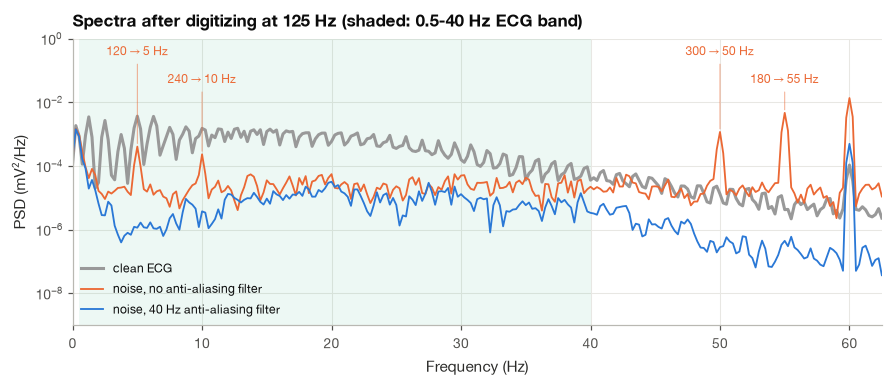

In [14]:
f_n, P_ecg = signal.welch(ecg_ref, fs_new, nperseg=4 * fs_new)
_, P_noise_noaa = signal.welch(x_noaa - ecg_ref, fs_new, nperseg=4 * fs_new)
_, P_noise_aa = signal.welch(x_aa - ecg_ref_aa, fs_new, nperseg=4 * fs_new)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.semilogy(f_n, P_ecg, color="0.6", lw=2, label="clean ECG")
ax.semilogy(f_n, P_noise_noaa, color=C[1], lw=1.2, label="noise, no anti-aliasing filter")
ax.semilogy(f_n, P_noise_aa, color=C[0], lw=1.2, label="noise, 40 Hz anti-aliasing filter")
for f, source, y_text in [(5, 120, 0.3), (10, 240, 0.04), (50, 300, 0.3), (55, 180, 0.04)]:
    peak = P_noise_noaa[np.argmin(abs(f_n - f))]
    ax.annotate(f"{source}" + r"$\rightarrow$" + f"{f} Hz", (f, peak), xytext=(f, y_text), ha="center", fontsize=8, color=C[1],
                arrowprops=dict(arrowstyle="-", color=C[1], lw=0.6, alpha=0.6))
ax.axvspan(0.5, 40, color=C[2], alpha=0.08, lw=0)
ax.set(xlabel="Frequency (Hz)", ylabel="PSD (mV$^2$/Hz)", xlim=(0, 62.5), ylim=(1e-9, 1),
       title="Spectra after digitizing at 125 Hz (shaded: 0.5-40 Hz ECG band)")
ax.legend(loc="lower left", fontsize=8)
plt.show()

Without the filter, sharp lines appear at exactly the frequencies predicted by equation [(11.18)](#eq-11-18), each labeled with the harmonic it came from, and the folded high-frequency muscle noise raises the whole noise floor by roughly a factor of ten in power below 10 Hz, where the P and T waves live. With the filter, the in-band noise is the in-band muscle noise that was there all along; nothing new has been added. The waveforms make the difference tangible.

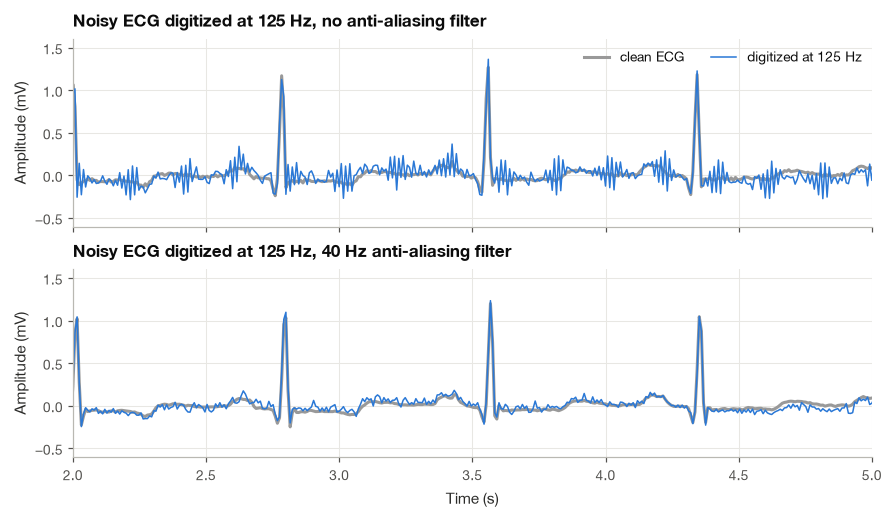

In [15]:
t_n = np.arange(x_noaa.size) / fs_new
fig, axes = plt.subplots(2, 1, figsize=(8, 4.6), sharex=True, sharey=True)
for ax, x, ref, label in [(axes[0], x_noaa, ecg_ref, "no anti-aliasing filter"),
                          (axes[1], x_aa, ecg_ref_aa, "40 Hz anti-aliasing filter")]:
    ax.plot(t_n, ref, color="0.6", lw=2, label="clean ECG")
    ax.plot(t_n, x, color=C[0], lw=1, label="digitized at 125 Hz")
    ax.set(ylabel="Amplitude (mV)", xlim=(2, 5), title=f"Noisy ECG digitized at 125 Hz, {label}")
axes[0].legend(loc="upper right", ncol=2)
axes[1].set_xlabel("Time (s)")
plt.show()

### Step 6: Can a digital filter repair it afterwards?

A natural question is whether a good digital band-pass filter applied after sampling can make up for the missing analog one. We apply the same zero-phase 0.5–40 Hz band-pass to both digitized signals and to their clean references and measure the remaining error.

In [16]:
sos_bp = signal.butter(4, [0.5, 40], btype="bandpass", fs=fs_new, output="sos")


def rms_error_uv(x, ref):
    """RMS difference (uV) after identical zero-phase 0.5-40 Hz band-pass filtering."""
    return 1000 * np.sqrt(np.mean((signal.sosfiltfilt(sos_bp, x) - signal.sosfiltfilt(sos_bp, ref)) ** 2))


err_noaa = rms_error_uv(x_noaa, ecg_ref)
err_aa = rms_error_uv(x_aa, ecg_ref_aa)
print(f"in-band RMS noise, no anti-aliasing filter : {err_noaa:5.1f} uV")
print(f"in-band RMS noise, with anti-aliasing      : {err_aa:5.1f} uV")
print(f"ratio                                      : {20 * np.log10(err_noaa / err_aa):5.1f} dB")

in-band RMS noise, no anti-aliasing filter :  40.0 uV
in-band RMS noise, with anti-aliasing      :  24.0 uV
ratio                                      :   4.4 dB


Without the anti-aliasing filter the in-band noise is 40.0 µV RMS instead of 24.0 µV, almost three times the noise power. The digital band-pass removed the aliases at 50 and 55 Hz, which fell outside its passband, but it cannot touch the lines at 5 and 10 Hz or the folded muscle noise spread across the whole band: once aliased, they are indistinguishable from cardiac activity. The anti-aliasing filter has to be in front of the converter. Modern ECG chips often satisfy this requirement by **oversampling**: they sample at several kilohertz behind a gentle analog filter, then apply a sharp digital low-pass and decimate to the output rate, which moves most of the anti-aliasing work into the digital domain where it is cheap and precise.

(sec-11-2-7)=
## 11.2.7 Choosing the Sampling Rate

Diagnostic electrocardiographs typically sample at 500 Hz or more, which comfortably supports the 150 Hz bandwidth recommended for adult diagnostic ECGs {cite:p}`kligfield2007`; bedside monitors commonly use about 250 Hz, Holter recorders 128 to 360 Hz, and many wearables less. A rate can be "enough" for one purpose and inadequate for another, and two effects decide which. Sampling too slowly *smooths* the QRS complex, because the anti-aliasing filter must remove the high frequencies that make it sharp, and it *quantizes time*, because the R peak can only be located on the sampling grid.

### What the grid does to R-peak timing

If the true peak falls at a random position between two samples, the error of picking the nearest sample is uniformly distributed on $[-T_s/2, T_s/2]$. The variance of a uniform distribution of width $T_s$ is

(eq-11-19)=
\begin{equation*}
\sigma_t^2 = \frac{1}{T_s}\int_{-T_s/2}^{T_s/2} e^2\,de = \frac{1}{T_s}\cdot\frac{2}{3}\left(\frac{T_s}{2}\right)^3 = \frac{T_s^2}{12},
\qquad \sigma_t = \frac{T_s}{\sqrt{12}}. \tag{11.19}
\end{equation*}

At 125 Hz this is $8/\sqrt{12} = 2.3$ ms. The timing error can be reduced far below the grid spacing by **parabolic interpolation**: fit a parabola $y = a\delta^2 + b\delta + c$ through the sample at the peak ($\delta = 0$) and its two neighbors ($\delta = \pm 1$). Writing the three samples as $y_{-1}, y_0, y_1$, the fit gives $c = y_0$, $b = (y_1 - y_{-1})/2$ and $a = (y_1 - 2y_0 + y_{-1})/2$, and setting the derivative $2a\delta + b$ to zero locates the vertex at

(eq-11-20)=
\begin{equation*}
\delta^* = -\frac{b}{2a} = \frac{y_{-1} - y_1}{2\,(y_{-1} - 2y_0 + y_1)}, \qquad
y^* = y_0 - \frac{(y_{-1} - y_1)\,\delta^*}{4}, \tag{11.20}
\end{equation*}

in units of samples. The second expression follows from substituting $\delta^*$ back into the parabola.

### Step 1: Build a reference with known R-peak times

We again use the 9 kHz band-limited reconstruction of record 100 as a stand-in for the continuous signal, now over five minutes. The "true" R-peak time and amplitude of each beat are taken on this fine grid. Because the original recording was sampled at 360 Hz, this reference cannot tell us anything about rates above 360 Hz that the data did not already contain, but it is a fair reference for the lower rates that wearables use.

In [17]:
rec = wfdb.rdrecord("../data/mitdb/100", sampto=360 * 300, channels=[0])
ann = wfdb.rdann("../data/mitdb/100", "atr", sampto=360 * 300)
is_beat = np.isin(ann.symbol, ["N", "A", "V"])
beats, labels = ann.sample[is_beat], np.array(ann.symbol)[is_beat]
keep = (beats > 360) & (beats < rec.sig_len - 360)
beats, labels = beats[keep], labels[keep]
x_mv = rec.p_signal[:, 0] - np.median(rec.p_signal[:, 0])       # amplitudes above the baseline
ecg_fine = signal.resample_poly(x_mv, up, 1)                    # 9 kHz

half = int(0.05 * fs_a)
true_idx = np.array([b * up - half + np.argmax(ecg_fine[b * up - half:b * up + half]) for b in beats])
true_t, true_amp = true_idx / fs_a, ecg_fine[true_idx]
print(f"{beats.size} beats ({np.sum(labels == 'N')} normal), mean R amplitude {true_amp.mean():.3f} mV")

369 beats (365 normal), mean R amplitude 1.245 mV


### Step 2: Resample at lower rates and locate the peaks

For each rate we resample the reference with a proper anti-aliasing filter (`resample_poly` applies a windowed-sinc low-pass), find each R peak as the largest sample near the true time, and refine it with equation [(11.20)](#eq-11-20).

In [18]:
def parabolic_peak(y, k):
    """Sub-sample peak position and height from three samples, equation (17.20)."""
    ym, y0, yp = y[k - 1], y[k], y[k + 1]
    delta = 0.5 * (ym - yp) / (ym - 2 * y0 + yp)
    return k + delta, y0 - 0.25 * (ym - yp) * delta


def rmssd(times, labels):
    """RMSSD (ms) using only successive differences formed by three consecutive normal beats."""
    normal = labels == "N"
    ok = normal[:-2] & normal[1:-1] & normal[2:]
    return 1000 * np.sqrt(np.mean(np.diff(np.diff(times))[ok] ** 2))


rmssd_true = rmssd(true_t, labels)
print(f"RMSSD from the reference peak times: {rmssd_true:.1f} ms")
rows = []
for fs_test in [500, 360, 250, 200, 125, 100, 50]:
    x_s = signal.resample_poly(ecg_fine, 1, fs_a // fs_test)
    t_grid, t_par, a_grid = [], [], []
    for tt in true_t:
        c = int(round(tt * fs_test))
        w0 = c - max(2, int(0.02 * fs_test))
        k = w0 + np.argmax(x_s[w0:c + max(3, int(0.02 * fs_test)) + 1])
        t_grid.append(k / fs_test)
        a_grid.append(x_s[k])
        t_par.append(parabolic_peak(x_s, k)[0] / fs_test)
    e_grid = 1000 * (np.array(t_grid) - true_t)
    e_par = 1000 * (np.array(t_par) - true_t)
    rows.append({"fs (Hz)": fs_test, "SD grid (ms)": e_grid.std(),
                 "Ts/sqrt(12) (ms)": 1000 / fs_test / np.sqrt(12),
                 "SD parabolic (ms)": e_par.std(),
                 "R ampl. error (%)": 100 * np.mean(np.array(a_grid) / true_amp - 1),
                 "RMSSD (ms)": rmssd(np.array(t_grid), labels),
                 "RMSSD pred. (ms)": np.sqrt(rmssd_true ** 2 + (1000 / fs_test) ** 2 / 2)})
timing = pd.DataFrame(rows)
print(timing.round(2).to_string(index=False))

RMSSD from the reference peak times: 26.2 ms


 fs (Hz)  SD grid (ms)  Ts/sqrt(12) (ms)  SD parabolic (ms)  R ampl. error (%)  RMSSD (ms)  RMSSD pred. (ms)
     500          0.58              0.58               0.07              -0.20       26.25             26.28
     360          0.80              0.80               0.12              -0.42       26.23             26.31
     250          1.19              1.15               0.19              -1.00       26.29             26.39
     200          1.43              1.44               0.24              -1.50       26.40             26.48
     125          2.34              2.31               0.46              -3.60       26.74             26.84
     100          2.95              2.89               0.67              -6.88       26.83             27.17
      50          5.92              5.77               1.80             -33.21       30.69             29.81


### Step 3: Read the results

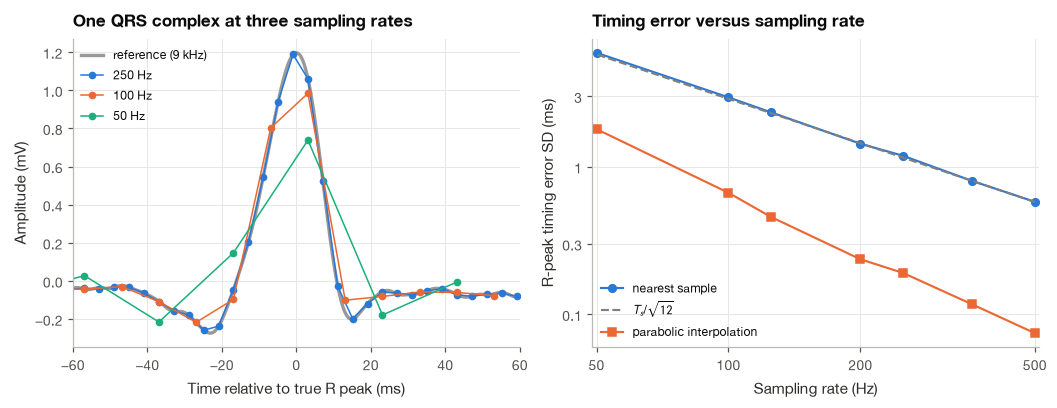

In [19]:
beat_k = 40
c = true_idx[beat_k]
win_fine = slice(c - int(0.06 * fs_a), c + int(0.06 * fs_a))
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
ax = axes[0]
ax.plot(1000 * (np.arange(win_fine.start, win_fine.stop) - c) / fs_a, ecg_fine[win_fine], color="0.6",
        lw=2.2, label="reference (9 kHz)")
for k, fs_test in enumerate([250, 100, 50]):
    x_s = signal.resample_poly(ecg_fine, 1, fs_a // fs_test)
    n = np.arange(int((true_t[beat_k] - 0.06) * fs_test), int((true_t[beat_k] + 0.06) * fs_test) + 1)
    ax.plot(1000 * (n / fs_test - true_t[beat_k]), x_s[n], "o-", color=C[k], ms=4, lw=1,
            label=f"{fs_test} Hz")
ax.set(xlabel="Time relative to true R peak (ms)", ylabel="Amplitude (mV)", xlim=(-60, 60),
       title="One QRS complex at three sampling rates")
ax.legend(loc="upper left", fontsize=8)

ax = axes[1]
ax.loglog(timing["fs (Hz)"], timing["SD grid (ms)"], "o-", color=C[0], label="nearest sample")
ax.loglog(timing["fs (Hz)"], timing["Ts/sqrt(12) (ms)"], "--", color="0.5", label=r"$T_s/\sqrt{12}$")
ax.loglog(timing["fs (Hz)"], timing["SD parabolic (ms)"], "s-", color=C[1], label="parabolic interpolation")
ax.set(xlabel="Sampling rate (Hz)", ylabel="R-peak timing error SD (ms)", title="Timing error versus sampling rate")
ax.set_xticks([50, 100, 200, 500], labels=["50", "100", "200", "500"])
ax.set_yticks([0.1, 0.3, 1, 3], labels=["0.1", "0.3", "1", "3"])
ax.minorticks_off()
ax.legend(loc="lower left", fontsize=8)
plt.show()

Three results stand out. First, the measured timing error follows the $T_s/\sqrt{12}$ law of equation [(11.19)](#eq-11-19) almost exactly, and parabolic interpolation reduces it four- to eightfold at rates of 100 Hz and above. Second, the R amplitude is underestimated by about 4 % at 125 Hz, 7 % at 100 Hz and a third at 50 Hz, both because the sample rarely lands on the peak and because the anti-aliasing filter blunts the complex; amplitude-based features such as R-wave voltage criteria are therefore not comparable across devices with different rates. Third, the timing jitter inflates beat-to-beat variability measures. If each R time carries an independent error of variance $\sigma_t^2$, each successive RR difference $(t_{k+1} - t_k) - (t_k - t_{k-1}) = t_{k+1} - 2t_k + t_{k-1}$ carries an error of variance $(1 + 4 + 1)\sigma_t^2 = 6\sigma_t^2$, so

$$
\mathrm{RMSSD}_{\text{measured}}^2 \approx \mathrm{RMSSD}_{\text{true}}^2 + 6\sigma_t^2 = \mathrm{RMSSD}_{\text{true}}^2 + \frac{T_s^2}{2}.
$$

The last two columns of the table check this prediction. We computed the RMSSD only from successive differences of three consecutive normal beats, as heart rate variability analysis requires (the reason is explained in Section 19.2). At 50 Hz the added term is $20^2/2 = 200$ ms$^2$, which should lift the RMSSD of this five-minute segment from 26.2 to 29.8 ms; the measured value is 30.7 ms, slightly more because the strong anti-aliasing filter at this rate also distorts the QRS. The bias does not depend on the subject, so it matters most when the true variability is small: for a true RMSSD of 10 ms the same 200 ms$^2$ would give $\sqrt{100 + 200} \approx 17$ ms, an overestimate of 70 %. This is the reason behind the heart rate variability guideline of sampling at 250 to 500 Hz, or interpolating the R-peak position when lower rates must be used {cite:p}`taskforce1996`. 

(sec-11-2-8)=
## 11.2.8 Amplitude Resolution: The ADC

The converter also quantizes amplitude, as developed in general in Section 9.4. The header of an MIT-BIH record stores everything needed to relate the stored integers to millivolts.

In [20]:
hdr = wfdb.rdheader("../data/mitdb/100")
gain, baseline, bits = hdr.adc_gain[0], hdr.baseline[0], hdr.adc_res[0]
lsb_uv = 1000 / gain
full_range_mv = 2 ** bits / gain
print(f"ADC resolution : {bits} bits ({2 ** bits} levels)")
print(f"gain           : {gain:.0f} ADC units per mV, baseline {baseline} units")
print(f"LSB            : {lsb_uv:.1f} uV, full range {full_range_mv:.2f} mV")
print(f"quantization noise RMS (LSB / sqrt(12)) : {lsb_uv / np.sqrt(12):.2f} uV")

rec_d = wfdb.rdrecord("../data/mitdb/100", sampto=3600, channels=[0], physical=False)
rec_p = wfdb.rdrecord("../data/mitdb/100", sampto=3600, channels=[0])
p_from_d = (rec_d.d_signal[:, 0] - baseline) / gain
print(f"max |p_signal - (d_signal - baseline)/gain| = {np.max(np.abs(rec_p.p_signal[:, 0] - p_from_d)):.1e} mV")

ADC resolution : 11 bits (2048 levels)
gain           : 200 ADC units per mV, baseline 1024 units
LSB            : 5.0 uV, full range 10.24 mV
quantization noise RMS (LSB / sqrt(12)) : 1.44 uV
max |p_signal - (d_signal - baseline)/gain| = 0.0e+00 mV


The MIT-BIH data were digitized with 11 bits over a 10.24 mV range, so one step is 5 µV and the quantization noise has an RMS of about 1.4 µV, far below the electrode and amplifier noise of any real recording. To see where quantization starts to matter, we requantize one second of record 100 to coarser converters with the same range.

In [21]:
def requantize(x, bits, full_range):
    """Round x (mV) to a uniform quantizer with the given number of bits over a symmetric range."""
    lsb = full_range / 2 ** bits
    return np.clip(np.round(x / lsb) * lsb, -full_range / 2, full_range / 2 - lsb), lsb


x_sec = rec_p.p_signal[360:720, 0] - np.median(rec_p.p_signal[:, 0])
rows, versions = [], {}
for b_test in [11, 8, 6]:
    xq, lsb = requantize(x_sec, b_test, full_range_mv)
    versions[b_test] = xq
    err = xq - x_sec
    rows.append([b_test, 1000 * lsb, 1000 * err.std(), 1000 * lsb / np.sqrt(12)])
print(pd.DataFrame(rows, columns=["bits", "LSB (uV)", "measured error RMS (uV)", "LSB/sqrt(12) (uV)"])
      .round(2).to_string(index=False))

 bits  LSB (uV)  measured error RMS (uV)  LSB/sqrt(12) (uV)
   11       5.0                     0.00               1.44
    8      40.0                    11.37              11.55
    6     160.0                    46.60              46.19


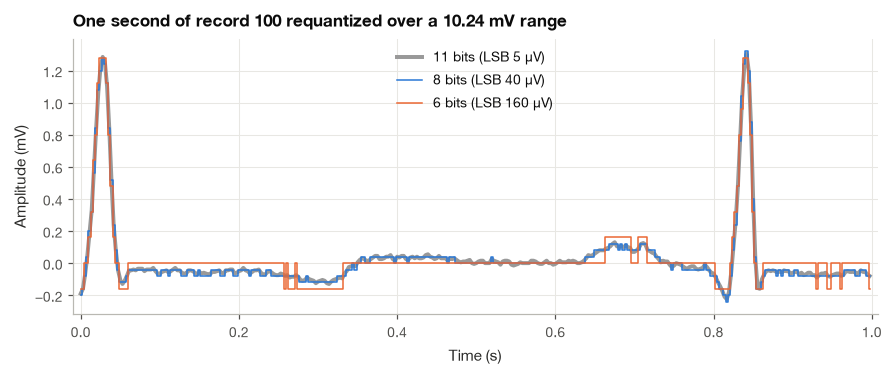

In [22]:
t_sec = np.arange(x_sec.size) / 360
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.plot(t_sec, versions[11], color="0.6", lw=2.6, label="11 bits (LSB 5 µV)")
ax.step(t_sec, versions[8], where="mid", color=C[0], lw=1, label="8 bits (LSB 40 µV)")
ax.step(t_sec, versions[6], where="mid", color=C[1], lw=1, label="6 bits (LSB 160 µV)")
ax.set(xlabel="Time (s)", ylabel="Amplitude (mV)", title="One second of record 100 requantized over a 10.24 mV range")
ax.legend(loc="upper center")
plt.show()

The 11-bit row reports zero error because the data are already on that grid. With 8 bits the P and T waves survive but carry visible steps; with 6 bits the P wave is a single step and the T wave has nearly vanished. The measured error RMS matches the $\mathrm{LSB}/\sqrt{12}$ rule once the LSB is small compared with the signal's local variations, which is the assumption behind that rule.

Modern ECG front ends usually go the other way: a 24-bit sigma-delta converter with an input range of a few volts digitizes the signal *DC-coupled*, electrode offset and all, with steps well below a microvolt. The high-pass filtering of Section 11.2.5 then happens in software, where it can be zero-phase and can be changed after the fact. The price is that the digital pipeline, the subject of [Chapter 12](../ch18_ecg_preprocessing/index.md), has more to do.

```{important}
Before analyzing any ECG dataset, find out its sampling rate, its analog passband and its ADC gain and resolution from the documentation or the header. A 0.5 Hz causal high-pass, a 125 Hz rate without interpolation or an 8-bit converter each limit what can be measured, and no later algorithm can recover what the hardware discarded.
```

## Summary

The ECG reaching an algorithm has passed through electrodes, an amplifier, filters and a converter, and each leaves a mark. Ag/AgCl electrodes with gel convert ionic to electronic current with low noise but introduce half-cell offsets of up to hundreds of millivolts and an impedance that motion and drying change. The three-op-amp instrumentation amplifier has a differential gain $G_1 R_3/R_2$ and a common-mode rejection of roughly $G_1 \cdot 2/\varepsilon$ for a resistor mismatch $\varepsilon$, yet electrode impedance mismatch converts common-mode voltage into a differential error $v_c\,\Delta Z_e/Z_{cm}$, which is why input impedance must be high and why the right-leg drive reduces the common-mode voltage itself. AC coupling with a first-order high-pass shifts the ST segment by about $-2\pi f_c A_{\text{QRS}}$, which we confirmed on record 100 and which explains the 0.05 Hz diagnostic recommendation. Re-digitizing a real noisy ECG at 125 Hz showed mains harmonics folding to 5 and 10 Hz without an anti-aliasing filter, an error that no digital filter could remove afterwards. Finally, R-peak timing jitter follows $T_s/\sqrt{12}$, inflates RMSSD by $T_s^2/2$ in the mean square and is largely cured by parabolic interpolation, while amplitude resolution of 11 bits at 5 µV per step is ample for the ECG.

[Section 11.3](03_ecg_data_in_python.ipynb) turns from hardware to files and shows how PhysioNet stores everything we have just discussed. The digital counterparts of the analog filters (baseline removal, low-pass filtering, power-line cancellation) are built step by step in [Chapter 12](../ch18_ecg_preprocessing/index.md).

## Exercises

1. A three-op-amp instrumentation amplifier has $R_1 = 49.9$ kΩ, $R_g = 1$ kΩ and a unity-gain output stage. Compute its differential gain. If the output stage resistors have a worst-case mismatch of 0.1 %, estimate the overall CMRR in dB.
2. Using equation [(11.15)](#eq-11-15), find the minimum common-mode input impedance needed to keep the 50 Hz error below 10 µV when the body carries 200 mV of common-mode voltage and the electrode impedances differ by 500 kΩ (a realistic mismatch for dry electrodes).
3. Derive the rule of thumb [(11.17)](#eq-11-17) more carefully for a rectangular QRS of height $H$ and duration $D$, without assuming $D \ll \tau$. Show that the output just after the QRS is $-H(1 - e^{-D/\tau})$ and that this reduces to $-HD/\tau$ for $D \ll \tau$.
4. List the alias frequencies of the first five harmonics of 50 Hz mains when an ECG is sampled at 128 Hz without an anti-aliasing filter. Which of them fall in the 0.5–40 Hz band?
5. Repeat the experiment of Section 11.2.6 with $f_s = 100$ Hz and an anti-aliasing filter whose corner sits at 45 Hz. How much attenuation does a fourth-order Butterworth provide at the lowest frequency that aliases into the 0.5–40 Hz band? Would a second-order filter be enough?
6. Extend the timing experiment of Section 11.2.7 to records 119 and 208. Does the R amplitude error at 125 Hz differ between normal beats and premature ventricular beats? Explain your answer in terms of the spectral content of wide and narrow QRS complexes.

## Further Reading

{cite:t}`webster2010` is the standard reference for biopotential electrodes and amplifiers, including the skin–electrode equivalent circuit, the instrumentation amplifier, the potential-divider effect and right-leg drive. The recommended bandwidths and filter settings for diagnostic electrocardiographs are set out by {cite:t}`kligfield2007`, and the sampling requirements for heart rate variability by {cite:t}`taskforce1996`. {cite:t}`moody2001` describe how the MIT-BIH recordings were made and digitized, and {cite:t}`moody1984` describe the noise stress test recordings used in Step 1 of Section 11.2.6.